In [1]:
!pip -q install tensorflow scikit-learn pandas numpy matplotlib


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf


In [3]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from google.colab import files


In [4]:
np.random.seed(42)


In [5]:
tf.random.set_seed(42)


In [8]:
print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully")

TensorFlow version: 2.21.0
Libraries imported successfully


In [9]:
uploaded = files.upload()

file_path = next(
    name for name in uploaded
    if name.endswith(".txt")
)


Saving household_power_consumption.txt to household_power_consumption.txt


In [10]:
df = pd.read_csv(
    file_path,
    sep=";",
    na_values=["?"],
    low_memory=False
)

print("Original dataset shape:", df.shape)
display(df.head())
print(df.isnull().sum())

Original dataset shape: (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64


In [11]:
df["Datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    dayfirst=True,
    errors="coerce"
)

df = df.drop(columns=["Date", "Time"])
df = df.dropna(subset=["Datetime"])
df = df.sort_values("Datetime")
df = df.drop_duplicates(subset=["Datetime"])
df = df.set_index("Datetime")

for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.replace([np.inf, -np.inf], np.nan)

df = df.interpolate(method="time", limit_direction="both")
df = df.dropna()

# Keep consecutive one-minute timestamps
minute_gaps = df.index.to_series().diff().ne(
    pd.Timedelta(minutes=1)
)
groups = minute_gaps.cumsum()

selected = None

for _, group in df.groupby(groups, sort=False):
    if len(group) >= 10000:
        selected = group.iloc[:10000].copy()
        break

if selected is None:
    raise ValueError(
        "No 10,000-row contiguous minute window found."
    )

df = selected

print("Selected rows:", len(df))
print("Start:", df.index.min())
print("End:", df.index.max())
print("Missing values:", int(df.isnull().sum().sum()))

df.to_csv("electricity_sample.csv")

Selected rows: 10000
Start: 2006-12-16 17:24:00
End: 2006-12-23 16:03:00
Missing values: 0


In [12]:
target_col = "Global_active_power"
feature_cols = df.select_dtypes(include=np.number).columns.tolist()

split_index = int(len(df) * 0.8)

feature_scaler = MinMaxScaler()
target_scaler = MinMaxScaler()

feature_scaler.fit(df[feature_cols].iloc[:split_index])
target_scaler.fit(df[[target_col]].iloc[:split_index])

X_scaled = feature_scaler.transform(df[feature_cols])
y_scaled = target_scaler.transform(df[[target_col]]).ravel()

print("Features:", feature_cols)
print("Training rows:", split_index)
print("Testing rows:", len(df) - split_index)

Features: ['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']
Training rows: 8000
Testing rows: 2000


In [13]:
SEQUENCE_LENGTH = 60

X, y, target_indices = [], [], []

for i in range(SEQUENCE_LENGTH, len(df)):
    X.append(X_scaled[i-SEQUENCE_LENGTH:i])
    y.append(y_scaled[i])
    target_indices.append(i)

X = np.asarray(X, dtype=np.float32)
y = np.asarray(y, dtype=np.float32)
target_indices = np.asarray(target_indices)

train_mask = target_indices < split_index
test_mask = target_indices >= split_index

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Sequence length:", SEQUENCE_LENGTH)

X_train: (7940, 60, 7)
X_test: (2000, 60, 7)
Sequence length: 60


In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([
    tf.keras.Input(
        shape=(SEQUENCE_LENGTH, len(feature_cols))
    ),
    LSTM(32, return_sequences=True),
    Dropout(0.2),
    LSTM(16),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 32)         │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 16)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,273 (32.32 KB)

 Trainable params: 8,273 (32.32 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - loss: 0.0403 - mae: 0.1279 - val_loss: 0.0054 - val_mae: 0.0392
Epoch 2/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - loss: 0.0083 - mae: 0.0625 - val_loss: 0.0039 - val_mae: 0.0383
Epoch 3/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - loss: 0.0066 - mae: 0.0534 - val_loss: 0.0030 - val_mae: 0.0339
Epoch 4/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - loss: 0.0058 - mae: 0.0488 - val_loss: 0.0026 - val_mae: 0.0317
Epoch 5/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - loss: 0.0054 - mae: 0.0464 - val_loss: 0.0022 - val_mae: 0.0271
Epoch 6/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - loss: 0.0051 - mae: 0.0455 - val_loss: 0.0023 - val_mae: 0.0304
Epoch 7/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - loss: 0.0052 - mae: 0.0453 - val_loss: 0.0021 - val_mae: 0.0279
Epoch 8/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - loss: 0.0048 - mae: 0.0437 - val_loss: 0.0021 - val_mae: 0.0296
Epoch 9/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/

In [15]:
pred_scaled = model.predict(X_test, verbose=0)

y_actual = target_scaler.inverse_transform(
    y_test.reshape(-1, 1)
).ravel()

y_predicted = target_scaler.inverse_transform(
    pred_scaled
).ravel()

mae = mean_absolute_error(y_actual, y_predicted)
rmse = np.sqrt(mean_squared_error(y_actual, y_predicted))

print(f"MAE:  {mae:.4f} kW")
print(f"RMSE: {rmse:.4f} kW")

MAE:  0.5748 kW
RMSE: 0.7648 kW


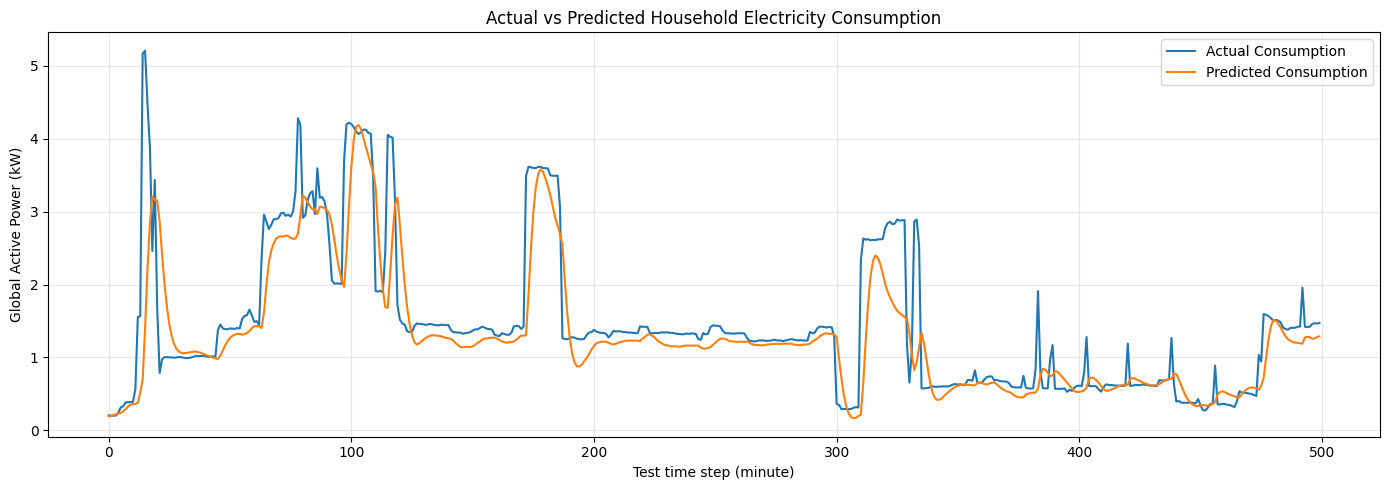

In [16]:
plt.figure(figsize=(14, 5))

plt.plot(
    y_actual[:500],
    label="Actual Consumption",
    linewidth=1.5
)

plt.plot(
    y_predicted[:500],
    label="Predicted Consumption",
    linewidth=1.5
)

plt.title("Actual vs Predicted Household Electricity Consumption")
plt.xlabel("Test time step (minute)")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("actual_vs_predicted.png", dpi=150)
plt.show()

In [17]:
demo_count = min(10, len(X_test))

demo_scaled = model.predict(
    X_test[-demo_count:],
    verbose=0
)

demo_actual = target_scaler.inverse_transform(
    y_test[-demo_count:].reshape(-1, 1)
).ravel()

demo_predicted = target_scaler.inverse_transform(
    demo_scaled
).ravel()

demo = pd.DataFrame({
    "Actual_Consumption_kW": demo_actual,
    "Predicted_Consumption_kW": demo_predicted
})

display(demo.round(4))

,Actual_Consumption_kW,Predicted_Consumption_kW
0,4.808,3.7764
1,4.840,3.9466
2,4.396,4.0573
3,2.890,4.1065
4,3.672,3.8205
5,4.958,3.6781
6,4.954,3.7861
7,4.932,3.9364
8,4.926,4.0740
9,4.658,4.1802


In [18]:
model.save("electricity_lstm.keras")

predictions = pd.DataFrame({
    "Actual_Consumption_kW": y_actual,
    "Predicted_Consumption_kW": y_predicted
})

predictions.to_csv("predictions.csv", index=False)

print("Model and predictions saved successfully.")
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))

Model and predictions saved successfully.
MAE: 0.5748
RMSE: 0.7648


In [19]:
files.download("electricity_sample.csv")
files.download("actual_vs_predicted.png")
files.download("predictions.csv")
files.download("electricity_lstm.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>